## Put your name and student ID here:

**Name:** Laurie Gantuangco

**Student ID:** 1771419

## AI-assistance disclosure

GitHub Copilot (agent mode in VS Code) was used for this notebook. It helped in the following ways:

- **Implementing the TODOs.** It wrote the code for every TODO: the `TimestepEmbedder` MLP and sinusoidal embedding, the `LabelEmbedder` table, the adaLN-Zero modulation in `DiTBlock.forward`, the `NoiseSchedule` (β, α, ᾱ and `add_noise`), and the `sample_ddim` sampler.
- **Explaining the code.** It wrote the `Solution` comments under each TODO that describe how that part works.
- **Running the notebook.** It ran the training, test and FID cells on a local GPU and checked the saved sample images.
- **Debugging the FID.** The provided training loop gave an FID of about 40 at 8 DDIM steps. Copilot ran side experiments (other 8-step timestep spacings, clipping the predicted clean image, more sampling steps, longer training with a learning-rate decay) and found that the sampler was not the cause. It then added a cosine learning-rate decay to the training loop, which brought the FID under 30. This is the only change to the provided code; it is marked with a comment in the training cell.
- **Local setup.** The notebook was run locally instead of on Colab: the Google Drive mount cell was removed, `project_path` points to a local folder, and `!pip` was changed to `%pip` in the torchmetrics install cell.

In [4]:
import os
import math
import torch

import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt
import torch.nn.functional as F

from tqdm import tqdm
from pathlib import Path
from collections import defaultdict
from torchvision.utils import make_grid
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from timm.models.vision_transformer import (Mlp,
                                            Attention,
                                            PatchEmbed)

In [5]:
project_path = Path('/home/laurie/CMPUT328/Assignment4')

dataset_path = project_path / 'datasets'

## Loading the FashionMNIST training dataset

In [6]:
batch_size = 32

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize(32),
    transforms.Normalize(
        mean=(0.5),
        std=(0.5),
    ),
])

train_dataset = datasets.FashionMNIST(
    root=dataset_path,
    train=True,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True,
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.42MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 39.0MB/s]


### Visualizing the samples

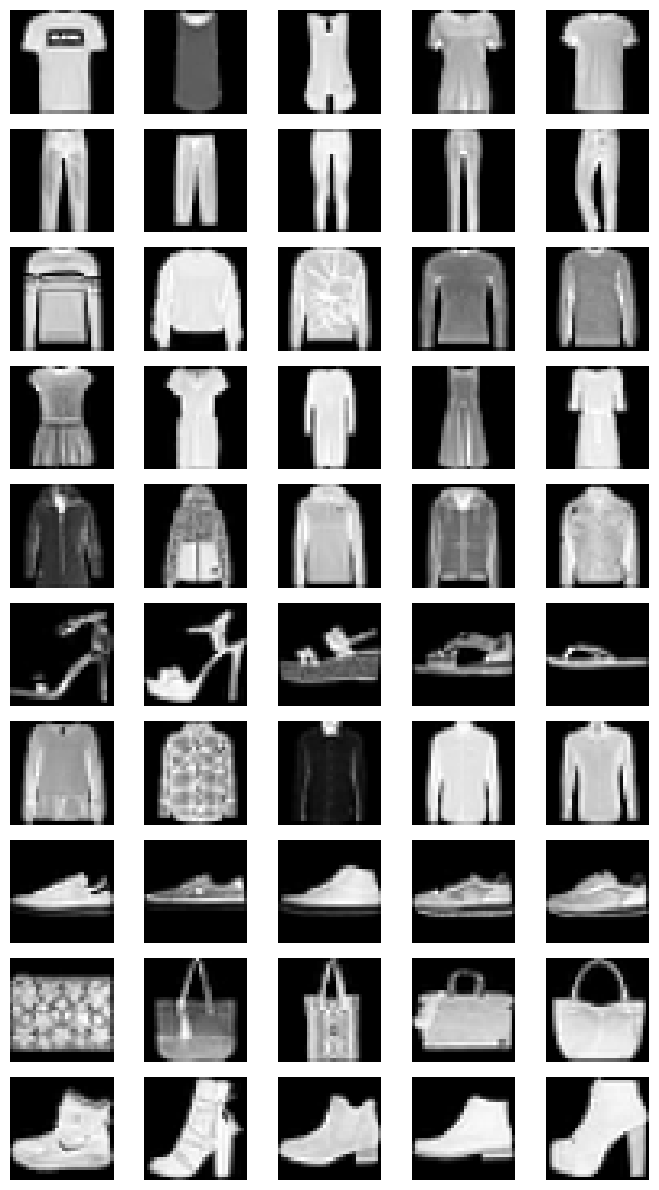

In [9]:
class_names = train_dataset.classes

# Store samples for each class
samples_per_class = defaultdict(list)

for image, label in train_dataset:
    if len(samples_per_class[label]) < 5:
        samples_per_class[label].append((image * 0.5 + 0.5).clamp(-1, 1))

    # Stop once every class has 5 samples
    if all(len(samples_per_class[c]) == 5 for c in range(10)):
        break

fig, axes = plt.subplots(10, 5, figsize=(7, 12))
for label in range(10):
    for i in range(5):
        image = samples_per_class[label][i]

        # Convert tensor (C, H, W) to (H, W, C)
        image = image.squeeze(0)

        axes[label, i].imshow(image, cmap='gray')
        axes[label, i].axis('off')

        if i == 0:
            axes[label, i].set_ylabel(
                class_names[label],
                fontsize=10
            )

plt.tight_layout()
plt.show()

## DO NOT CHANGE: Utility functions for Diffusion Transformers (taken from [DiT Github Repo](https://github.com/facebookresearch/dit))

In [10]:
def get_2d_sincos_pos_embed(embed_dim, grid_size, cls_token=False, extra_tokens=0):
    """
    grid_size: int of the grid height and width
    return:
    pos_embed: [grid_size*grid_size, embed_dim] or [1+grid_size*grid_size, embed_dim] (w/ or w/o cls_token)
    """
    grid_h = np.arange(grid_size, dtype=np.float32)
    grid_w = np.arange(grid_size, dtype=np.float32)
    grid = np.meshgrid(grid_w, grid_h)  # here w goes first
    grid = np.stack(grid, axis=0)

    grid = grid.reshape([2, 1, grid_size, grid_size])
    pos_embed = get_2d_sincos_pos_embed_from_grid(embed_dim, grid)
    if cls_token and extra_tokens > 0:
        pos_embed = np.concatenate([np.zeros([extra_tokens, embed_dim]), pos_embed], axis=0)
    return pos_embed


def get_2d_sincos_pos_embed_from_grid(embed_dim, grid):
    assert embed_dim % 2 == 0

    # use half of dimensions to encode grid_h
    emb_h = get_1d_sincos_pos_embed_from_grid(embed_dim // 2, grid[0])  # (H*W, D/2)
    emb_w = get_1d_sincos_pos_embed_from_grid(embed_dim // 2, grid[1])  # (H*W, D/2)

    emb = np.concatenate([emb_h, emb_w], axis=1) # (H*W, D)
    return emb


def get_1d_sincos_pos_embed_from_grid(embed_dim, pos):
    """
    embed_dim: output dimension for each position
    pos: a list of positions to be encoded: size (M,)
    out: (M, D)
    """
    assert embed_dim % 2 == 0
    omega = np.arange(embed_dim // 2, dtype=np.float64)
    omega /= embed_dim / 2.
    omega = 1. / 10000**omega  # (D/2,)

    pos = pos.reshape(-1)  # (M,)
    out = np.einsum('m,d->md', pos, omega)  # (M, D/2), outer product

    emb_sin = np.sin(out) # (M, D/2)
    emb_cos = np.cos(out) # (M, D/2)

    emb = np.concatenate([emb_sin, emb_cos], axis=1)  # (M, D)
    return emb



## Implementation of TimestepEmbedder, LableEmbedder, and AdaLN modulation for DiT

### **Part1 : TimestepEmbedder (10%)**
The skeleton of the time embedding module is provided to you. You need to complete two parts for this class
1. **(3%)**```self.mlp``` which maps the sinusoidally embedded time vector to the specified hidden size (3%)
2. **(7%)**```timestep_embedding``` function which receives the time $t$ and a target dimension ```dim``` and returns the sinusoidally embedded time vector


### **Part2 : LabelEmbedder (5%)**
The skeleton of the label embedding module is provided to you. You only need to complete the ```self.embedding_table``` in the module's constructor.

In [11]:
def modulate(x, shift, scale):
    return x * (1 + scale.unsqueeze(1)) + shift.unsqueeze(1)

class TimestepEmbedder(nn.Module):
    """
    Embeds scalar timesteps into vector representations.
    """
    def __init__(self, hidden_size, frequency_embedding_size=256):
        super().__init__()
        # TODO: Implement a two-layer MLP with SiLU activation
        # for mapping the frequency_embedding_size to hidden size
        # Solution: Linear -> SiLU -> Linear. The first layer lifts the sinusoidal
        # features (frequency_embedding_size) to hidden_size and the second keeps
        # that width. The layers must sit at indices 0 and 2 of the Sequential,
        # because DiT.initialize_weights() re-initializes mlp[0] and mlp[2].
        self.mlp = nn.Sequential(
            nn.Linear(frequency_embedding_size, hidden_size, bias=True),
            nn.SiLU(),
            nn.Linear(hidden_size, hidden_size, bias=True),
        )

        self.frequency_embedding_size = frequency_embedding_size

    @staticmethod
    def timestep_embedding(t, dim, max_period=10000):
        """
        Create sinusoidal timestep embeddings.
        :param t: a 1-D Tensor of N indices, one per batch element.
                          These may be fractional.
        :param dim: the dimension of the output.
        :param max_period: controls the minimum frequency of the embeddings.
        :return: an (N, D) Tensor of positional embeddings.
        """
        # TODO: Implement the sinusoidal time embedding
        # Solution: same construction as Transformer positional encodings.
        # 1. Build dim/2 frequencies spaced geometrically from 1 down to
        #    1/max_period: freq_i = max_period^(-i / half), computed in log
        #    space for numerical stability.
        half = dim // 2
        freqs = torch.exp(
            -math.log(max_period)
            * torch.arange(half, dtype=torch.float32, device=t.device)
            / half
        )

        # 2. Outer product of timesteps and frequencies: (N, 1) * (1, half)
        #    gives one phase per (timestep, frequency) pair.
        args = t[:, None].float() * freqs[None]

        # 3. Concatenating cos and sin of each phase gives an (N, dim) vector
        #    that encodes t at many scales, so nearby and distant timesteps are
        #    both easy for the MLP to tell apart.
        embedding = torch.cat([torch.cos(args), torch.sin(args)], dim=-1)

        # 4. For odd dim, cos+sin only yields dim-1 columns, so pad with a zero.
        if dim % 2:
            embedding = torch.cat(
                [embedding, torch.zeros_like(embedding[:, :1])], dim=-1
            )

        return embedding

    def forward(self, t):
        t_freq = self.timestep_embedding(t, self.frequency_embedding_size)
        t_emb = self.mlp(t_freq)
        return t_emb


class LabelEmbedder(nn.Module):
    """
    Embeds class labels into vector representations
    """
    def __init__(self, num_classes, hidden_size):
        super().__init__()

        # TODO: Create an embedding table mapping num_classes to hidden_size
        # Hint: Use nn.Embedding
        # Solution: a learnable lookup table with one hidden_size-dim row per
        # class. Its width matches the timestep embedding so that DiT.forward()
        # can add the two together to form the conditioning vector c = t + y.

        self.embedding_table = nn.Embedding(num_classes, hidden_size)

        self.num_classes = num_classes

    def forward(self, labels):
        embeddings = self.embedding_table(labels)
        return embeddings



## Implementation of a single DiT block

Below is the implementation of a single DiT block. Please do not change the implementation inside ```__init__```. You only need to complete the ```forward()``` function of the module. In the forward function, ```x``` is the input image/feature map and ```c``` is any input context.

### **Part 1: Context modulation (30%)**
Using the *shift*, *scale*, and *gate* coefficients computed at the first line of the forward method, you need to complete the DiT forward call which mixes the features and context information.

**Hint:** You need to use the ```modulate``` function defined in the block above.

In [12]:
class DiTBlock(nn.Module):
    """
    A DiT block with adaptive layer norm zero (adaLN-Zero) conditioning.
    """
    def __init__(self, hidden_size, num_heads, mlp_ratio=4.0, **block_kwargs):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden_size, elementwise_affine=False, eps=1e-6)
        self.attn = Attention(hidden_size, num_heads=num_heads, qkv_bias=True, **block_kwargs)
        self.norm2 = nn.LayerNorm(hidden_size, elementwise_affine=False, eps=1e-6)
        mlp_hidden_dim = int(hidden_size * mlp_ratio)
        approx_gelu = lambda: nn.GELU(approximate='tanh')
        self.mlp = Mlp(in_features=hidden_size, hidden_features=mlp_hidden_dim, act_layer=approx_gelu, drop=0)
        self.adaLN_modulation = nn.Sequential(
            nn.SiLU(),
            nn.Linear(hidden_size, 6 * hidden_size, bias=True)
        )

    def forward(self, x, c):
        shift_msa, scale_msa, gate_msa, shift_mlp, scale_mlp, gate_mlp = self.adaLN_modulation(c).chunk(6, dim=1)

        # Solution (both TODOs): each sub-layer is a pre-norm residual branch,
        #     x = x + gate * f(modulate(norm(x), shift, scale))
        # - The LayerNorms have no learnable affine parameters; modulate()
        #   supplies a per-sample scale and shift predicted from the context c
        #   (timestep + label), which is how the conditioning enters the block.
        # - gate multiplies the branch output before it joins the residual
        #   stream. The adaLN layer is zero-initialized, so every gate starts at
        #   0 and each block starts out as the identity function (adaLN-Zero).
        # - shift/scale/gate are (N, D) while x is (N, T, D), so gate needs
        #   unsqueeze(1) to broadcast over tokens (modulate() does the same).

        # TODO: Implement time-modulation for attention bock
        x = x + gate_msa.unsqueeze(1) * self.attn(
            modulate(self.norm1(x), shift_msa, scale_msa)
        )
        # TODO: Implement time-modulation for MLP bock
        x = x + gate_mlp.unsqueeze(1) * self.mlp(
            modulate(self.norm2(x), shift_mlp, scale_mlp)
        )

        return x

## DO NOT CHANGE: Implementation of Diffusion Transformers

In [13]:
class FinalLayer(nn.Module):
    """
    The final layer of DiT.
    """
    def __init__(self, hidden_size, patch_size, out_channels):
        super().__init__()
        self.norm_final = nn.LayerNorm(hidden_size, elementwise_affine=False, eps=1e-6)
        self.linear = nn.Linear(hidden_size, patch_size * patch_size * out_channels, bias=True)
        self.adaLN_modulation = nn.Sequential(
            nn.SiLU(),
            nn.Linear(hidden_size, 2 * hidden_size, bias=True)
        )

    def forward(self, x, c):
        shift, scale = self.adaLN_modulation(c).chunk(2, dim=1)
        x = modulate(self.norm_final(x), shift, scale)
        x = self.linear(x)
        return x


class DiT(nn.Module):
    """
    Diffusion model with a Transformer backbone.
    """
    def __init__(
        self,
        input_size=32,
        patch_size=2,
        in_channels=4,
        hidden_size=1152,
        depth=28,
        num_heads=16,
        mlp_ratio=4.0,
        class_dropout_prob=0.1,
        num_classes=1000,
        learn_sigma=False,
    ):
        super().__init__()
        self.learn_sigma = learn_sigma
        self.in_channels = in_channels
        self.out_channels = in_channels * 2 if learn_sigma else in_channels
        self.patch_size = patch_size
        self.num_heads = num_heads

        self.x_embedder = PatchEmbed(input_size, patch_size, in_channels, hidden_size, bias=True)
        self.t_embedder = TimestepEmbedder(hidden_size)
        self.y_embedder = LabelEmbedder(num_classes, hidden_size)
        num_patches = self.x_embedder.num_patches
        # Will use fixed sin-cos embedding:
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, hidden_size), requires_grad=False)

        self.blocks = nn.ModuleList([
            DiTBlock(hidden_size, num_heads, mlp_ratio=mlp_ratio) for _ in range(depth)
        ])
        self.final_layer = FinalLayer(hidden_size, patch_size, self.out_channels)
        self.initialize_weights()

    def initialize_weights(self):
        # Initialize transformer layers:
        def _basic_init(module):
            if isinstance(module, nn.Linear):
                torch.nn.init.xavier_uniform_(module.weight)
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)
        self.apply(_basic_init)

        # Initialize (and freeze) pos_embed by sin-cos embedding:
        pos_embed = get_2d_sincos_pos_embed(self.pos_embed.shape[-1], int(self.x_embedder.num_patches ** 0.5))
        self.pos_embed.data.copy_(torch.from_numpy(pos_embed).float().unsqueeze(0))

        # Initialize patch_embed like nn.Linear (instead of nn.Conv2d):
        w = self.x_embedder.proj.weight.data
        nn.init.xavier_uniform_(w.view([w.shape[0], -1]))
        nn.init.constant_(self.x_embedder.proj.bias, 0)

        # Initialize label embedding table:
        nn.init.normal_(self.y_embedder.embedding_table.weight, std=0.02)

        # Initialize timestep embedding MLP:
        nn.init.normal_(self.t_embedder.mlp[0].weight, std=0.02)
        nn.init.normal_(self.t_embedder.mlp[2].weight, std=0.02)

        # Zero-out adaLN modulation layers in DiT blocks:
        for block in self.blocks:
            nn.init.constant_(block.adaLN_modulation[-1].weight, 0)
            nn.init.constant_(block.adaLN_modulation[-1].bias, 0)

        # Zero-out output layers:
        nn.init.constant_(self.final_layer.adaLN_modulation[-1].weight, 0)
        nn.init.constant_(self.final_layer.adaLN_modulation[-1].bias, 0)
        nn.init.constant_(self.final_layer.linear.weight, 0)
        nn.init.constant_(self.final_layer.linear.bias, 0)

    def unpatchify(self, x):
        """
        x: (N, T, patch_size**2 * C)
        imgs: (N, H, W, C)
        """
        c = self.out_channels
        p = self.x_embedder.patch_size[0]
        h = w = int(x.shape[1] ** 0.5)
        assert h * w == x.shape[1]

        x = x.reshape(shape=(x.shape[0], h, w, p, p, c))
        x = torch.einsum('nhwpqc->nchpwq', x)
        imgs = x.reshape(shape=(x.shape[0], c, h * p, h * p))
        return imgs

    def forward(self, x, t, y):
        """
        Forward pass of DiT.
        x: (N, C, H, W) tensor of spatial inputs (images or latent representations of images)
        t: (N,) tensor of diffusion timesteps
        y: (N,) tensor of class labels
        """
        x = self.x_embedder(x) + self.pos_embed  # (N, T, D), where T = H * W / patch_size ** 2
        t = self.t_embedder(t)                   # (N, D)
        y = self.y_embedder(y)    # (N, D)
        c = t + y                                # (N, D)
        for block in self.blocks:
            x = block(x, c)                      # (N, T, D)
        x = self.final_layer(x, c)                # (N, T, patch_size ** 2 * out_channels)
        x = self.unpatchify(x)                   # (N, out_channels, H, W)
        return x


## Implementation of the noise scheduling

You need to complete the NoiseSchedule class provided below which is responsible for adding noise to the input image at a timestep $t$

### **Part 1: Computing $\beta$, $\alpha$, and $\bar\alpha$ (5%)**
Use the diffusion formulas to complete the ```__init__``` method.

### **Part 2: Noise Corruption (10%)**
Complete the ```add_noise``` method to corrupt the input image ```x``` with noise and return the noisy image at timestep $t$

In [14]:
class NoiseSchedule:
    def __init__(
        self,
        num_steps=1000,
        beta_start=1e-4,
        beta_end=0.02,
        device='cuda',
    ):
        self.num_steps = num_steps
        self.device = torch.device(device)

        # TODO: Linearly interpolate from beta_start to beta_end
        # Solution: beta_t is the variance of the noise added at step t. The
        # DDPM linear schedule spaces num_steps values evenly between the two
        # endpoints. It is created on `device` so indexing with GPU timesteps works.
        self.betas = torch.linspace(
            beta_start, beta_end, num_steps, device=self.device
        )

        # TODO: Compute alphas from betas
        # Solution: alpha_t = 1 - beta_t is the fraction of signal variance
        # kept by a single forward step.
        self.alphas = 1.0 - self.betas

        # TODO: Compute alpha_bars from alphas
        # Solution: alpha_bar_t = prod_{s<=t} alpha_s is the fraction of signal
        # kept after t steps, which lets us jump from x_0 to x_t in one shot.
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

    def extract(self, values, t, x_shape):
        """
        Extract schedule values for each batch element.

        values:  (T,)
        t:       (B,)
        returns: (B, 1, 1, 1) for image inputs
        """
        out = values[t]
        return out.reshape(t.shape[0], *([1] * (len(x_shape) - 1)))

    def add_noise(self, x0, t, noise=None):
        """
        Sample x_t from q(x_t | x_0).
        """
        if noise is None:
            # TODO: Sample random noise
            # Solution: standard Gaussian noise with the same shape, dtype and
            # device as x0. This is the target the network learns to predict.
            noise = torch.randn_like(x0)

        # TODO: Compute the corrupted image at time t
        # Solution: closed form of the forward process,
        #     q(x_t | x_0) = N(sqrt(alpha_bar_t) * x_0, (1 - alpha_bar_t) * I)
        # so x_t = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * noise.
        # extract() picks each sample's alpha_bar_t and reshapes it to
        # (B, 1, 1, 1) so it broadcasts over the image dimensions.
        alpha_bar_t = self.extract(self.alpha_bars, t, x0.shape)
        xt = alpha_bar_t.sqrt() * x0 + (1.0 - alpha_bar_t).sqrt() * noise

        return xt, noise


## Implementation of a DDIM sampler
Please do not change the arguments of the ```sample_ddim``` function provided below.

### **Part 1: Implementation of DDIM sampler (35%)**
In this part, you need to complete the ```sample_ddim``` function below by implementing the *DDIM* sampling algorithm with zero variance

In [15]:
@torch.no_grad()
def sample_ddim(
    model,
    noise_scheduler,
    labels,
    num_channels=1,
    image_size=32,
    num_steps=50,
    device='cuda',
):
    """
    Generate FashionMNIST images using deterministic DDIM sampling.

    labels:
        Tensor of shape (B,), containing class IDs 0-9.
    """
    device = torch.device(device)
    model.eval()

    batch_size = labels.shape[0]
    labels = labels.to(device)

    # Start from Gaussian noise.
    x = torch.randn(
        batch_size,
        num_channels,
        image_size,
        image_size,
        device=device,
    )

    # TODO: Implement DDIM sampling to update x
    # Solution: DDIM with eta = 0 (zero variance), i.e. a deterministic sampler.
    #
    # 1. DDIM does not have to visit all T training timesteps. Pick an evenly
    #    spaced, decreasing subsequence of num_steps timesteps from T-1 to 0.
    alpha_bars = noise_scheduler.alpha_bars.to(device)
    timesteps = torch.linspace(
        noise_scheduler.num_steps - 1, 0, num_steps, device=device
    ).long()

    for i, t in enumerate(timesteps):
        # 2. Predict the noise in x_t. The model expects one timestep per sample.
        t_batch = torch.full((batch_size,), t.item(), device=device, dtype=torch.long)
        predicted_noise = model(x, t_batch, labels)

        # 3. alpha_bar at the current timestep and at the next one in the
        #    subsequence. After the last step we land on the clean image, where
        #    no noise is left, so alpha_bar_prev = 1.
        alpha_bar_t = alpha_bars[t]
        if i + 1 < num_steps:
            alpha_bar_prev = alpha_bars[timesteps[i + 1]]
        else:
            alpha_bar_prev = torch.ones((), device=device)

        # 4. Invert the forward process x_t = sqrt(ab_t) x_0 + sqrt(1 - ab_t) eps
        #    to get the model's current estimate of the clean image x_0.
        x0_pred = (x - (1.0 - alpha_bar_t).sqrt() * predicted_noise) / alpha_bar_t.sqrt()

        # 5. Re-noise that estimate to the previous timestep with the SAME
        #    predicted noise instead of fresh random noise. This is the DDIM
        #    update with sigma_t = 0, so the stochastic term vanishes:
        #    x_prev = sqrt(ab_prev) * x0_pred + sqrt(1 - ab_prev) * eps
        x = alpha_bar_prev.sqrt() * x0_pred + (1.0 - alpha_bar_prev).sqrt() * predicted_noise

    return x.clamp(-1, 1)

## DO NOT CHANGE: Training utility functions

The following ```save_generations``` function is used to save the images generated by the Diffusion Model throughout training or at the inference time.

In [16]:
def save_generations(model, noise_scheduler, path, labels = None):
    if labels is None:
        labels = torch.tensor(
            list(range(9)),
            device=device,
        )

    samples = sample_ddim(
        model=model,
        noise_scheduler=noise_scheduler,
        labels=labels,
        num_steps=50
    )

    samples = (samples + 1) / 2

    grid = make_grid(
        samples.cpu(),
        nrow=2,
        padding=2,
    )

    plt.figure(figsize=(7, 4))
    plt.imsave(path, grid.permute(1, 2, 0).clamp(0, 1))
    plt.axis('off')
    plt.close()

## Main training loop

The complete training loop is given to you. The parameters are tested to make sure the model learns to generate FashionMNIST-like samples. However, feel free to play around with the parameters.

**NOTE** Fo final submission make sure that you have not changed the architecture of the network.

In [ ]:
device = torch.device('cuda')
epochs = 20
save_every = 5
lr = 3e-4

output_dir = project_path / 'outputs' / 'diffusion'
output_dir.mkdir(parents=True, exist_ok=True)

checkpoint_dir = output_dir / 'checkpoints'
checkpoint_dir.mkdir(parents=True, exist_ok=True)

network_cfg = {
    'input_size': 32,
    'patch_size': 4,
    'in_channels': 1,
    'hidden_size': 256,
    'depth': 6,
    'num_heads': 8,
    'mlp_ratio':4.,
    'num_classes': 10,

}

# Defining the model
model = DiT(**network_cfg).to(device)

# Defining the noise scheduling
noise_scheduler = NoiseSchedule(
    num_steps=1000,
    device=device,
)

# Defining the optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=lr,
    betas=(0.9, 0.999),
    weight_decay=0.0,
)

# Added (not in the provided loop): cosine learning-rate decay to zero.
# With a constant lr of 3e-4 the 8-step DDIM FID was ~40 (above the 30
# threshold) even though samples looked fine; decaying the lr lets the
# weights settle at the end of training. The architecture is unchanged.
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs * len(train_loader),
)

history = []


for epoch in range(1, epochs + 1):
    model.train()

    running_loss = 0.0

    progress = tqdm(
        train_loader,
        desc=f'Epoch {epoch}/{epochs}',
    )

    for x0, labels in progress:
        x0 = x0.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        batch_size = x0.shape[0]

        # 1. Sample a random diffusion timestep.
        t = torch.randint(
            low=0,
            high=noise_scheduler.num_steps,
            size=(batch_size,),
            device=device,
        )

        # 2. Sample Gaussian noise and construct x_t.
        xt, noise = noise_scheduler.add_noise(x0, t)

        # 3. Predict the noise.
        predicted_noise = model(xt, t, labels)

        # 4. Noise-prediction objective.
        loss = F.mse_loss(predicted_noise, noise)

        # 5. Update the model.
        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        optimizer.step()
        lr_scheduler.step()

        running_loss += loss.item()

        progress.set_postfix(loss=f'{loss.item():.4f}')

    epoch_loss = running_loss / len(train_loader)
    history.append(epoch_loss)

    # Save checkpoints periodically.
    if epoch % save_every == 0 or epoch == epochs - 1 or epoch == 1:
        print(
            f'Epoch {epoch}/{epochs} | '
            f'Noise prediction MSE: {epoch_loss:.5f}'
        )
        torch.save(
            {
                'epoch': epoch,
                'model': model.state_dict(),
                'optimizer': optimizer.state_dict(),
                'loss': epoch_loss,
            },
            checkpoint_dir / f'checkpoint_{epoch:03d}.pt',
        )
        with torch.no_grad():
            save_generations(model, noise_scheduler, output_dir / f'epoch_{epoch:03d}.png')

Epoch 1/20: 100%|██████████| 1875/1875 [00:15<00:00, 119.96it/s, loss=0.0460]


Epoch 1/20 | Noise prediction MSE: 0.06782


Epoch 5/20: 100%|██████████| 1875/1875 [00:16<00:00, 115.75it/s, loss=0.0252]


Epoch 5/20 | Noise prediction MSE: 0.03282


Epoch 10/20: 100%|██████████| 1875/1875 [00:14<00:00, 127.15it/s, loss=0.0203]


Epoch 10/20 | Noise prediction MSE: 0.02836


... (2 outputs left out)

Epoch 19/20: 100%|██████████| 1875/1875 [00:14<00:00, 126.89it/s, loss=0.0289]


Epoch 19/20 | Noise prediction MSE: 0.02549


Epoch 20/20: 100%|██████████| 1875/1875 [00:14<00:00, 127.72it/s, loss=0.0195]


Epoch 20/20 | Noise prediction MSE: 0.02476


## Test the model

In [26]:
checkpoint = torch.load(
    checkpoint_dir / f'checkpoint_{epochs:03d}.pt',
    map_location=device,
)

model.load_state_dict(checkpoint['model'])
model.eval()

gen_imgs_dir = output_dir / 'generated'
gen_imgs_dir.mkdir(parents=True, exist_ok=True)

with torch.no_grad():
    for i in range(10):
      for j in range(10):
          labels = torch.tensor([i], device=device)
          save_generations(model, noise_scheduler, gen_imgs_dir / f'class_{i}_sample_{j}.png', labels)

## DO NOT CHANGE - Computing FID Score

### **Part 1: Compute the FID score (5%)**
Use the following code to compute the FID score of your model over the test set

**Note:** You'll get the mark of this part if your model gets an FID score under 30.

In [7]:
# Install torchmetrics
%pip install torchmetrics torchmetrics[image]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 31.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [torch-fidelity]m [torchmetrics]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
from torchmetrics.image.fid import FrechetInceptionDistance as FID

In [20]:
def prepare_image_for_fid(images):
    """
    Prepares a batch of Fashion-MNIST images for FID evaluation.

    Args:
        images (torch.Tensor): Shape (N, 1, 28, 28). Can be in range [0, 1] or [-1, 1].

    Returns:
        torch.Tensor: Shape (N, 3, 299, 299), dtype torch.uint8, range [0, 255].
    """
    # 1. Denormalize if your diffusion model outputs [-1, 1]
    # If your output is already [0, 1], skip this step
    if images.min() < 0:
        images = (images + 1.0) / 2.0

    # Ensure clipping to avoid out-of-bounds float values
    images = torch.clamp(images, 0.0, 1.0)

    # 2. Convert from 1 channel to 3 channels (Grayscale -> RGB)
    # Replicates the channel dimension along dim=1
    images_rgb = images.repeat(1, 3, 1, 1)

    # 3. Resize to 299x299 (Inception-v3 standard resolution)
    # Using bilinear or bicubic interpolation
    images_resized = F.interpolate(images_rgb, size=(299, 299), mode='bilinear', align_corners=False)

    # 4. Scale to uint8 [0, 255] range as expected by Torchmetrics FID
    images_uint8 = (images_resized * 255).to(torch.uint8)

    return images_uint8


In [27]:
test_dataset = datasets.FashionMNIST(
    root=dataset_path,
    train=False,
    download=True,
    transform=transform,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True,
)

fid = FID(feature=2048, normalize=False).to(device)

with torch.no_grad():
    for real_batch, labels in tqdm(test_loader):
        real_processed = prepare_image_for_fid(real_batch).to(device)
        generated_images = sample_ddim(model, noise_scheduler, labels, num_steps=8, device=device)
        generated_processed = prepare_image_for_fid(generated_images).to(device)
        fid.update(real_processed, real=True)
        fid.update(generated_processed, real=False)


# Compute final score
fid_score = fid.compute()
print(f'FID Score: {fid_score.item()}')

100%|██████████| 312/312 [00:24<00:00, 12.89it/s]


FID Score: 26.217729568481445
